# Target Variable Analysis

Sample Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

classification_df = pd.DataFrame({"Age": [22, 28, 35, 41, 29, 52, 33, 46, 38, 26, 31, 44], "Purchased": ["No", "No", "Yes", "No", "No", "Yes", "No", "No", "Yes", "No", "No", "No"]})
regression_df = pd.DataFrame({"Experience": list(range(1, 13)), "Salary": [30000, 33000, 35000, 39000, 42000, 46000, 49000, 53000, 57000, 61000, 65000, 120000]})
print("Classification sample:")
print(classification_df.head())
print("\nRegression sample:")
print(regression_df.head())


Classification sample:
   Age Purchased
0   22        No
1   28        No
2   35       Yes
3   41        No
4   29        No

Regression sample:
   Experience  Salary
0           1   30000
1           2   33000
2           3   35000
3           4   39000
4           5   42000


# 1. Class Distribution
# Definition
Class distribution describes how observations are divided among the labels of a classification target. It helps us see whether the classes are similarly represented or one class dominates. The target is categorical, such as Yes/No or Fraud/Not Fraud. A chart makes the overall pattern easy to recognize.

# Business Example
An online store checks how many customers purchased versus did not purchase. The business learns which outcome is more common in its historical records. If most visitors do not purchase, the company should interpret its conversion model accordingly. This distribution provides context for evaluating marketing decisions.

# AI/ML Use
Class distribution is checked before building a classification model. An uneven distribution may make accuracy misleading because a model can predict only the majority class. It helps guide stratified splitting and the choice of precision, recall, or F1-score. It also warns us to inspect the minority class carefully.

# Python Example

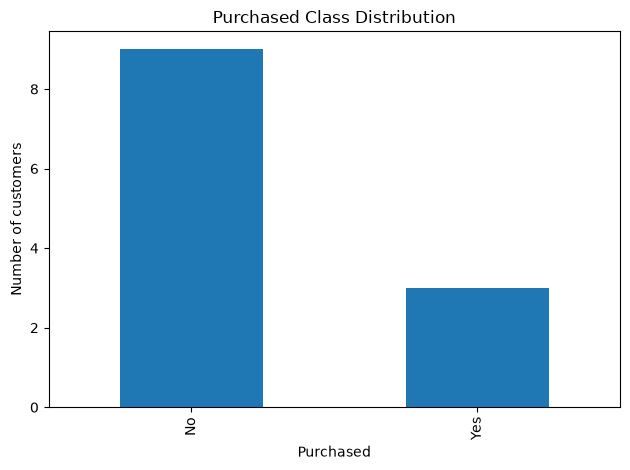

In [3]:
classification_df["Purchased"].value_counts().plot(kind="bar", title="Purchased Class Distribution")
plt.xlabel("Purchased")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Explanation
The bar heights show how many records belong to each target class. A taller bar means that outcome occurs more frequently in the sample. The plot helps reveal whether the classes are balanced. It does not by itself tell us how well a model will perform.

# 2. Class Counts
# Definition
Class counts are the number of records in each target class. They are absolute frequencies, not percentages. Counts show how much training information is available for each label. They are especially important when one class has very few examples.

# Business Example
A bank counts approved and rejected loan applications. These counts show the volume of each decision in its records. A very small rejected group may require closer analysis before automation. Counts help teams judge whether the dataset is representative.

# AI/ML Use
A classification model needs enough examples of each class to learn useful patterns. Small class counts can make predictions for rare outcomes unreliable. Counts guide train-test split checks and model evaluation. They are also useful for detecting changes between training and future data.

# Python Example

In [4]:
print(classification_df["Purchased"].value_counts())


Purchased
No     9
Yes    3
Name: count, dtype: int64


# Explanation
The output lists each target label with its number of observations. The counts add up to the total number of dataset rows. Here, No is more frequent than Yes. These counts are the basis for calculating class percentages.

# 3. Class Percentages
# Definition
Class percentages express each class count as a share of all target observations. Unlike raw counts, percentages are easy to compare across datasets of different sizes. All class percentages should add up to approximately 100%. They help communicate the balance of the target.

# Business Example
A telecom company reports the percentage of customers who churn. Managers can compare the churn rate between months even if the customer count changes. A percentage communicates the relative size of the churn group. It helps make business reports easier to understand.

# AI/ML Use
Class percentages help evaluate whether the target is imbalanced. They provide a baseline for interpreting model accuracy and recall. They also guide the selection of stratified sampling for classification. Comparing percentages across data splits can expose sampling problems.

# Python Example

In [5]:
print((classification_df["Purchased"].value_counts(normalize=True) * 100).round(2))

Purchased
No     75.0
Yes    25.0
Name: proportion, dtype: float64


# Explanation
The code divides each class count by the total number of records and multiplies by 100. The result shows the proportion of Yes and No cases. Larger percentages indicate more common classes. The values help describe target balance clearly.

# 4. Class Imbalance
# Definition
Class imbalance occurs when one target class has substantially more records than another. It is common in fraud detection, rare disease prediction, and customer churn. A high overall accuracy may hide poor performance on the minority class. Imbalance should be measured before model training.

# Business Example
A payment company may have many legitimate transactions but only a few fraudulent ones. Predicting every transaction as legitimate would appear accurate but fail to detect fraud. The business cares about correctly identifying the rare cases. Understanding imbalance helps set realistic success measures.

# AI/ML Use
Imbalanced targets require careful model evaluation using precision, recall, F1-score, or PR-AUC as appropriate. Stratified splits help preserve class proportions across train and test sets. Class weights or resampling may be considered on training data only. The appropriate approach depends on the cost of different errors.

# Python Example

In [6]:
counts = classification_df["Purchased"].value_counts()
print("Class counts:")
print(counts)
print("Majority/minority ratio:", round(counts.max() / counts.min(), 2))

Class counts:
Purchased
No     9
Yes    3
Name: count, dtype: int64
Majority/minority ratio: 3.0


# Explanation
The ratio compares the most common class with the least common class. A larger ratio signals greater imbalance. The sample shows that No appears more often than Yes. This is a reason to inspect minority-class performance rather than relying only on accuracy.

# 5. Target Distribution
# Definition
For regression, the target distribution shows how continuous target values are spread. A histogram reveals where values cluster and whether there are long tails. It can also highlight gaps or unusually high or low values. The shape can affect modeling and error analysis.

# Business Example
A company studies the distribution of employee salaries. Most salaries may be near a typical range, while a few senior roles earn much more. The business can see whether high salaries are unusual or common. This helps interpret workforce compensation patterns.

# AI/ML Use
Regression models predict numerical target values, so the target shape matters. A long right tail can cause a few large values to dominate squared-error metrics. A target transformation may be worth testing in some cases. Any transformation must be applied and reversed correctly when reporting predictions.

# Python Example

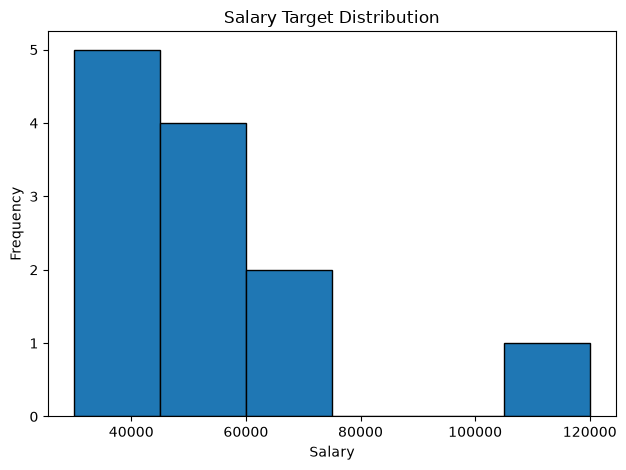

In [7]:
plt.hist(regression_df["Salary"], bins=6, edgecolor="black")
plt.title("Salary Target Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Explanation
The histogram groups salaries into value ranges. Taller bars represent ranges containing more observations. The high salary near the upper end stretches the distribution to the right. This suggests checking skewness and possible outliers.

# 6. Mean
# Definition
The mean is the arithmetic average of all numerical target values. It is calculated by dividing the sum of values by their count. The mean gives a single measure of the center of the distribution. Very large or small values can change it noticeably.

# Business Example
An HR team calculates the average salary across employees. The result gives a quick overall reference for payroll planning. However, a few highly paid employees may raise the average. The team should compare it with the median before drawing conclusions.

# AI/ML Use
For regression, the mean is a simple baseline prediction for a squared-error objective. Comparing a model against a mean baseline helps determine whether the model adds value. The mean can also be affected by extreme target values. It should be interpreted together with other descriptive statistics.

# Python Example

In [8]:
print("Mean salary:", round(regression_df["Salary"].mean(), 2))

Mean salary: 52500.0


# Explanation
The code adds all salary values and divides by the number of employees. The printed result is the average target value. The high salary in the sample pulls the mean upward. Comparing the mean with the median helps reveal that effect.

# 7. Median
# Definition
The median is the middle value after numerical observations are sorted. For an even number of values, it is the average of the two middle values. The median is less sensitive to extreme observations than the mean. It is useful when the target distribution is skewed.

# Business Example
A property company reports the median house price in a city. A few luxury properties may be extremely expensive. The median better reflects the middle transaction than the average in such cases. It gives buyers a practical reference point.

# AI/ML Use
For regression analysis, the median is a useful baseline for absolute-error objectives. Comparing mean and median can reveal target skewness. It is often informative when extreme target values are present. It does not replace examining the full distribution.

# Python Example

In [9]:
print("Median salary:", regression_df["Salary"].median())

Median salary: 47500.0


# Explanation
The code sorts the target values internally and finds the central value. The median is less influenced by the largest salary. If mean and median differ substantially, the target may be skewed. This helps decide which summary measure is most representative.

# 8. Variance
# Definition
Variance measures how far numerical target values spread around their mean, using squared differences. Higher variance means values are more dispersed. Variance is expressed in squared units, such as rupees squared for salary. Pandas uses sample variance by default.

# Business Example
A retail company examines variation in daily revenue. A high variance indicates that revenue changes considerably from day to day. Managers may need to plan for unstable cash flow. A low variance suggests revenue is more consistent.

# AI/ML Use
Target variance describes the range of outcomes a regression model must learn. It provides context for interpreting prediction errors. Large target variation can make accurate prediction harder in some settings. Variance should be compared only for compatible units and datasets.

# Python Example

In [10]:
print("Sample variance of salary:", round(regression_df["Salary"].var(), 2))

Sample variance of salary: 576818181.82


# Explanation
The code calculates the sample variance of salary using Pandas. It measures squared deviations from the mean. A large value indicates considerable spread in salaries. Because the units are squared, standard deviation is often easier to interpret.

# 9. Standard Deviation
# Definition
Standard deviation is the square root of variance. It measures the typical spread of numerical target values around their mean. Unlike variance, it uses the same units as the target. A larger standard deviation means the values vary more widely.

# Business Example
A manufacturing company checks the standard deviation of production time. A high value suggests jobs take very different amounts of time. A low value indicates a more consistent process. This helps managers estimate delivery reliability.

# AI/ML Use
Standard deviation provides scale information for a regression target. It helps judge whether a prediction error is large relative to normal target variation. It is also useful when comparing model performance across datasets with different target scales. Extreme observations can increase it.

# Python Example

In [11]:
print("Sample standard deviation of salary:", round(regression_df["Salary"].std(), 2))

Sample standard deviation of salary: 24017.04


# Explanation
The output measures salary spread in salary units. A larger value means salaries are farther from the average on the whole. The unusually high salary contributes to the spread. The result helps put regression errors into context.

# 10. Skewness
# Definition
Skewness measures whether a numerical distribution is asymmetric. Positive skewness indicates a longer right tail, while negative skewness indicates a longer left tail. A value near zero suggests approximate symmetry, though it does not prove normality. Skewness is useful for spotting uneven target distributions.

# Business Example
An insurance company examines claim amounts. Most claims may be small, with a few very large claims. This creates a right-skewed distribution. Understanding the shape helps the company plan for costly claims.

# AI/ML Use
A skewed regression target may cause some loss functions to focus heavily on large observations. Log transformation can sometimes help when the target is strictly positive. Models should be evaluated on the original business scale as well. Skewness alone does not justify transforming the target.

# Python Example

In [12]:
print("Salary skewness:", round(regression_df["Salary"].skew(), 2))

Salary skewness: 2.22


# Explanation
The code calculates the skewness of salary. A positive result means the upper tail extends farther than the lower tail. The unusually high salary produces right-skew in this sample. We should inspect the values before choosing a transformation.

# 11. Outliers
# Definition
Outliers are target values that differ substantially from most other observations. They may be genuine rare cases, measurement problems, or data-entry mistakes. Outliers can influence the mean, variance, and regression loss. They should be investigated rather than removed automatically.

# Business Example
An HR dataset contains one salary much higher than the others. It might belong to a senior executive and be entirely valid. It could also be an extra zero entered by mistake. The business should verify the record before making changes.

# AI/ML Use
Extreme target values can strongly affect regression training and evaluation. Detecting them helps decide whether to retain, correct, or separately study unusual cases. The IQR method is a simple screening rule, not proof of an error. Any removal decision should be documented and justified.

# Python Example

In [13]:
q1 = regression_df["Salary"].quantile(0.25)
q3 = regression_df["Salary"].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("IQR bounds:", round(low, 2), round(high, 2))
print("Potential outliers:")
print(regression_df.loc[(regression_df["Salary"] < low) | (regression_df["Salary"] > high), ["Experience", "Salary"]])

IQR bounds: 8000.0 88000.0
Potential outliers:
    Experience  Salary
11          12  120000


# Explanation
The code calculates the first and third quartiles and uses 1.5 times the IQR to flag unusual values. It prints records outside those bounds. These records are potential outliers, not automatically invalid data. The high salary should be verified before deciding whether to retain it.

# 12. Importance of Understanding the Target Before Machine Learning
Definition
Target variable analysis is the process of examining the outcome that a model is expected to predict. It checks the target type, frequency, distribution, spread, and unusual observations. Understanding the target helps match the problem to classification or regression. It also exposes problems that could make evaluation misleading.

# Business Example
A business predicting customer purchases first checks how often purchases happen. If purchases are rare, a model that always predicts No could appear accurate without helping the business. For salary prediction, the business examines the typical salary and very high salaries. This makes expectations about model quality more realistic.

# AI/ML Use
Target analysis guides the choice of task, metrics, and data splitting. For classification, class proportions affect stratification and the interpretation of precision and recall. For regression, skewness and outliers affect error metrics and possible transformations. This analysis should happen before training so decisions are grounded in the data.

# Python Example

In [14]:
print("Classification target percentages:")
print((classification_df["Purchased"].value_counts(normalize=True) * 100).round(1))
print("\nRegression target summary:")
print(regression_df["Salary"].describe())

Classification target percentages:
Purchased
No     75.0
Yes    25.0
Name: proportion, dtype: float64

Regression target summary:
count        12.000000
mean      52500.000000
std       24017.039406
min       30000.000000
25%       38000.000000
50%       47500.000000
75%       58000.000000
max      120000.000000
Name: Salary, dtype: float64


# Explanation
The first output shows the relative size of each classification label. The second output summarizes the numerical regression target, including its center and spread. These checks show whether classes are uneven or target values vary widely. They help choose sensible model evaluation methods before training.